IMPORT REQUIRED LIBRARIES

In [272]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


LOAD THE DATASET

In [273]:
df=pd.read_csv("/content/customer_churn_classification.csv")
df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,monthly_charges.1,tech_support,customer_id,gender,monthly_charges.2,monthly_charges.3,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,86.76,No,C10119,Male,86.76,86.76,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,109.03,No,C10012,Male,109.03,109.03,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,67.40,No,NaN,Female,67.40,67.40,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,81.81,NaN,NaN,ale,81.81,81.81,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,61.18,o,C10236,Fmale,61.18,61.18,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,51.0,26.0,Two year,DS,1286.98,101.71,101.71,NaN,C10203,Mal,101.71,101.71,0.0,Credit card
258,77.0,66.0,NaN,SL,6985.19,55.06,55.06,Yes,C10087,MALE,55.06,55.06,1.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,97.23,N,C10072,NaN,97.23,97.23,0.0,Credit card
260,48.0,62.0,MONTH-TO-MONTH,o,NaN,NaN,NaN,No,C10235,Female,NaN,NaN,NaN,Bank transfer


In [274]:
print("Original shape:", df.shape)
display(df.head())
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Original shape: (262, 14)


,age,tenure_months,contract,internet_service,total_charges,monthly_charges,monthly_charges.1,tech_support,customer_id,gender,monthly_charges.2,monthly_charges.3,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,86.76,No,C10119,Male,86.76,86.76,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,109.03,No,C10012,Male,109.03,109.03,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,67.40,No,NaN,Female,67.40,67.40,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,81.81,NaN,NaN,ale,81.81,81.81,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,61.18,o,C10236,Fmale,61.18,61.18,1.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                233 non-null    float64
 1   tenure_months      241 non-null    float64
 2   contract           236 non-null    object 
 3   internet_service   240 non-null    object 
 4   total_charges      238 non-null    float64
 5   monthly_charges    233 non-null    float64
 6   monthly_charges.1  233 non-null    float64
 7   tech_support       238 non-null    object 
 8   customer_id        239 non-null    object 
 9   gender             242 non-null    object 
 10  monthly_charges.2  233 non-null    float64
 11  monthly_charges.3  233 non-null    float64
 12  churn              236 non-null    float64
 13  payment_method     245 non-null    object 
dtypes: float64(8), object(6)
memory usage: 28.8+ KB

Missing values:
 age                  29
tenure_months        21
contract

REMOVE UNNECESSARY DUPLICATE COLOUMNS

In [275]:
df = df.drop_duplicates().copy()
df = df.drop(columns=["monthly_charges.1", "monthly_charges.2",
                      "monthly_charges.3"], errors="ignore")
df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,No,C10012,Male,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,No,NaN,Female,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,NaN,NaN,ale,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,o,C10236,Fmale,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
256,72.0,12.0,Month-to-month,NaN,6249.12,23.93,NO,C10133,Male,1.0,Credit card
257,51.0,26.0,Two year,DS,1286.98,101.71,NaN,C10203,Mal,0.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,N,C10072,NaN,0.0,Credit card
260,48.0,62.0,MONTH-TO-MONTH,o,NaN,NaN,No,C10235,Female,NaN,Bank transfer


HANDLING INCONSISTENT CATEGORICAL VALUES

In [276]:
df['gender'] = df['gender'].replace({
    'MALE': 'Male',
    'FEMALE': 'Female'
})

df['contract'] = df['contract'].replace({
    'MONTH-TO-MONTH': 'Month-to-month',
    'ONE YEAR': 'One year',
    'TWO YEAR': 'Two year'
})

df['internet_service'] = df['internet_service'].replace({
    'DSL': 'DSL',
    'Dsl': 'DSL',
    'NO': 'No',
    'FIBER OPTIC': 'Fiber optic'
})

df['tech_support'] = df['tech_support'].replace({
    'YES': 'Yes',
    'NO': 'No'
})

df['payment_method'] = df['payment_method'].replace({
    'BANK TRANSFER': 'Bank transfer',
    'CREDIT CARD': 'Credit card',
    'ELECTRONIC CHECK': 'Electronic check',
    'MAILED CHECK': 'Mailed check'
})

CORRECT SPELLING INCONSISTENCIES

In [277]:
df['contract'] = df['contract'].replace({
    'To year': 'Two year',
    'Twoyear': 'Two year',
    'Two yer': 'Two year',
    'Two yea': 'Two year',
    'Month-t-month': 'Month-to-month',
    'Month-to-monh': 'Month-to-month',
    'Moth-to-month': 'Month-to-month',
    'onth-to-month': 'Month-to-month',
    'Monh-to-month': 'Month-to-month',
    'Monthto-month': 'Month-to-month',
    'One ear': 'One year',
    'ne year': 'One year',
    'wo year': 'Two year'
})

df['internet_service'] = df['internet_service'].replace({
    'o': 'No',
    'N': 'No',
    'SL': 'DSL',
    'DL': 'DSL',
    'DS': 'DSL',
    'Fiber opti': 'Fiber optic',
    'Fiber ptic': 'Fiber optic',
    'Fiber optc': 'Fiber optic',
    'iber optic': 'Fiber optic',
    'Fibe optic': 'Fiber optic',
    'Fiberoptic': 'Fiber optic'
})

df['tech_support'] = df['tech_support'].replace({
    'o': 'No',
    'N': 'No',
    'Ys': 'Yes',
    'Ye': 'Yes',
    'es': 'Yes'
})

df['gender'] = df['gender'].replace({
    'ale': 'Male',
    'Mae': 'Male',
    'Mle': 'Male',
    'Mal': 'Male',
    'Femae': 'Female',
    'Fmale': 'Female',
    'emale': 'Female',
    'Femle': 'Female',
    'Femal': 'Female',
    'Feale': 'Female'
})

df['payment_method'] = df['payment_method'].replace({
    'Credt card': 'Credit card',
    'Cedit card': 'Credit card',
    'Credit cad': 'Credit card',
    'Crdit card': 'Credit card',
    'Bank tranfer': 'Bank transfer',
    'Bak transfer': 'Bank transfer',
    'Mailed ceck': 'Mailed check',
    'Maled check': 'Mailed check',
    'Maild check': 'Mailed check',
    'Electroni check': 'Electronic check',
    'Eletronic check': 'Electronic check'
})

HANDLE MISSING VALUES

1.FILL NUMERICAL MISSING VALUES

In [278]:
df.isnull().sum()
num_cols = [
    'age',
    'tenure_months',
    'total_charges',
    'monthly_charges'
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

2.FILL CATEGORICAL MISSING VALUES

In [279]:
cat_cols = [
    'contract',
    'internet_service',
    'tech_support',
    'gender',
    'payment_method'
]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

HANDLE MISSING CHURN AND CUSTOMER ID

In [280]:
df['churn'] = df['churn'].fillna(df['churn'].mode()[0])

df['customer_id'] = df['customer_id'].fillna('Unknown')

HANDLE OUTLIERS USING IQR

In [281]:
num_cols = [
    'age',
    'tenure_months',
    'total_charges',
    'monthly_charges'
]

for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

age Outliers: 0
tenure_months Outliers: 0
total_charges Outliers: 0
monthly_charges Outliers: 0


VISUALIZE OUTLIERS USING BOX PLOTS

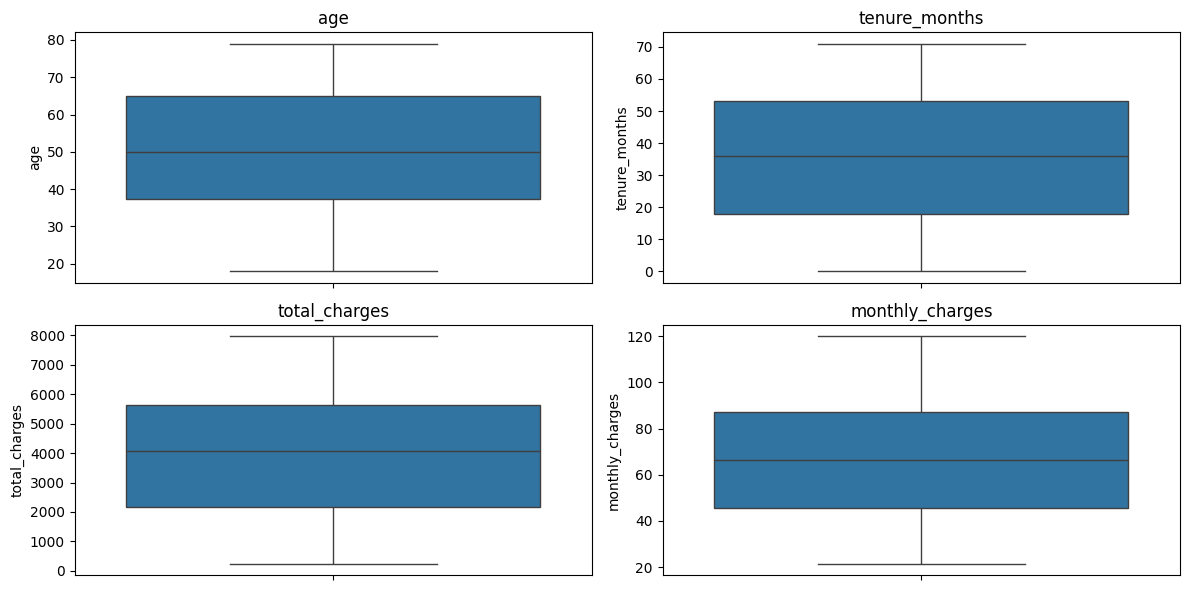

In [282]:
plt.figure(figsize=(12, 6))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

FINAL CLEANED DATASET

In [283]:
df.isnull().sum()

,0
age,0
tenure_months,0
contract,0
internet_service,0
total_charges,0
monthly_charges,0
tech_support,0
customer_id,0
gender,0
churn,0


CHECK DUPLICATES RECORDS

In [284]:
df.duplicated().sum()

np.int64(0)

DISPLAYING CLEANED DATASET

In [285]:
df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,50.0,34.0,Month-to-month,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,Fiber optic,3140.17,109.03,No,C10012,Male,1.0,Electronic check
2,50.0,49.0,Two year,Fiber optic,3434.07,67.40,No,Unknown,Female,1.0,Electronic check
3,34.0,62.0,One year,Fiber optic,341.26,81.81,Yes,Unknown,Male,1.0,Electronic check
4,52.0,24.0,Month-to-month,Fiber optic,3236.51,61.18,No,C10236,Female,1.0,Credit card
...,...,...,...,...,...,...,...,...,...,...,...
256,72.0,12.0,Month-to-month,Fiber optic,6249.12,23.93,No,C10133,Male,1.0,Credit card
257,51.0,26.0,Two year,DSL,1286.98,101.71,Yes,C10203,Male,0.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,No,C10072,Female,0.0,Credit card
260,48.0,62.0,Month-to-month,No,4087.27,66.25,No,C10235,Female,1.0,Bank transfer


In [286]:
df.head()

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,50.0,34.0,Month-to-month,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,Fiber optic,3140.17,109.03,No,C10012,Male,1.0,Electronic check
2,50.0,49.0,Two year,Fiber optic,3434.07,67.40,No,Unknown,Female,1.0,Electronic check
3,34.0,62.0,One year,Fiber optic,341.26,81.81,Yes,Unknown,Male,1.0,Electronic check
4,52.0,24.0,Month-to-month,Fiber optic,3236.51,61.18,No,C10236,Female,1.0,Credit card


SAVE THE CLEANED DATASET

In [287]:
df.to_csv("cleaned_customer_churn.csv", index=False)

print("Dataset cleaned and saved successfully")

Dataset cleaned and saved successfully


PERFORM DATA ANALYSIS

1.UNIVARIATE ANALYSIS


1.Age Distribution...

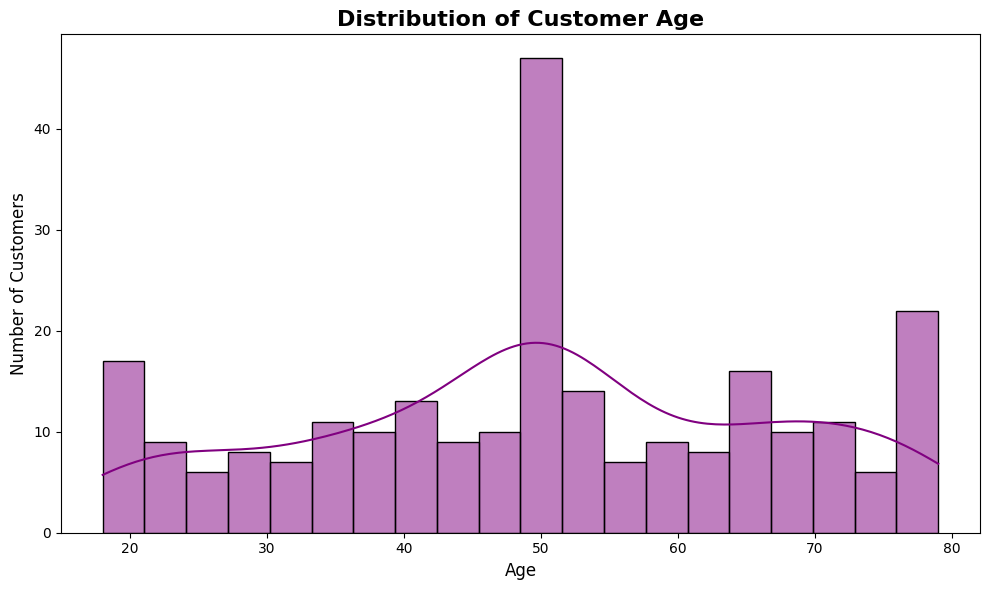

In [288]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    kde=True,
    color='purple',
    edgecolor='black'
)

plt.title('Distribution of Customer Age', fontsize=16, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

plt.tight_layout()
plt.show()

2.Count Plot

/tmp/ipykernel_546/3693872117.py:3: UserWarning: 
The palette list has fewer values (3) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(


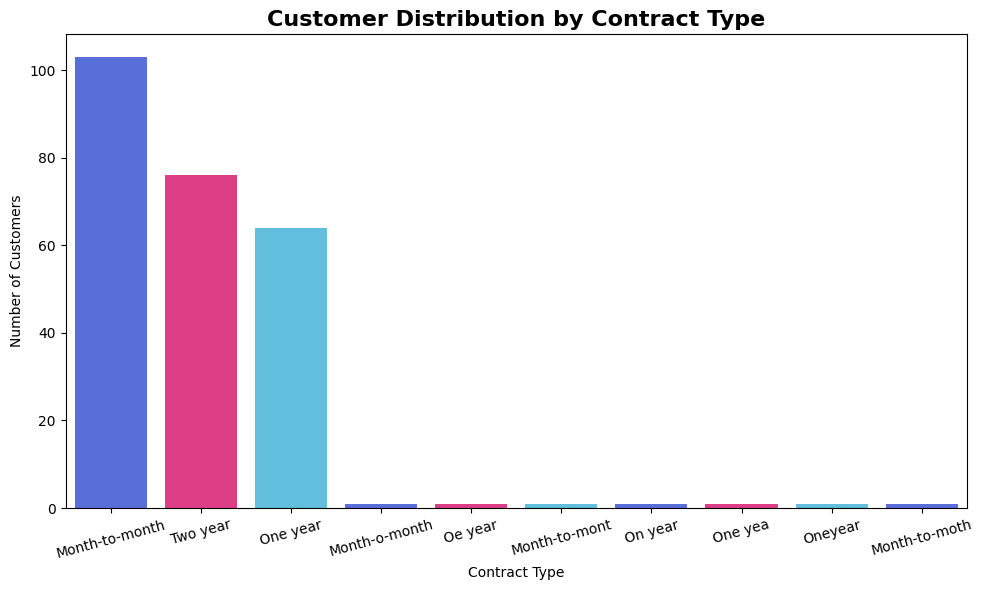

In [289]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='contract',
    hue='contract',
    palette=['#4361EE', '#F72585', '#4CC9F0'],
    legend=False
)

plt.title('Customer Distribution by Contract Type', fontsize=16, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

3. Box plot...

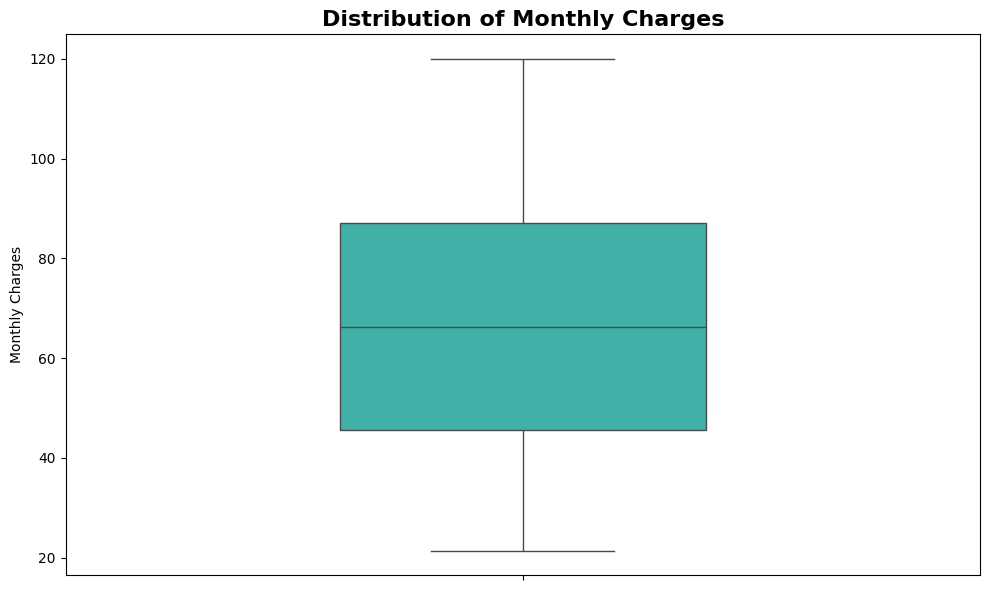

In [290]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    y='monthly_charges',
    color='#2EC4B6',
    width=0.4
)

plt.title('Distribution of Monthly Charges', fontsize=16, fontweight='bold')
plt.ylabel('Monthly Charges')

plt.tight_layout()
plt.show()

3. Pie chart...

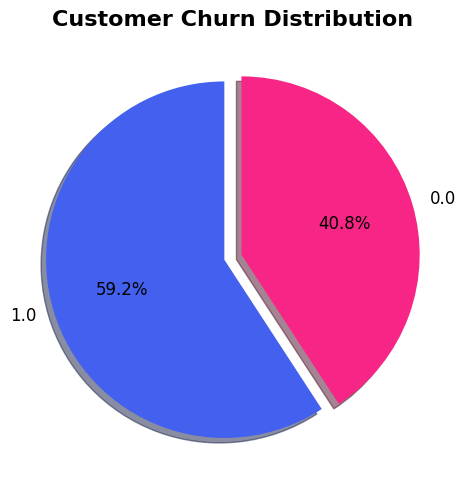

In [291]:
churn_counts = df['churn'].value_counts()

plt.figure(figsize=(5, 5))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#4361EE', '#F72585'],
    explode=[0.05] * len(churn_counts),
    shadow=True,
    textprops={'fontsize': 12}
)

plt.title('Customer Churn Distribution', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

2.BIVARIATE ANALYSIS

1.Box plot...

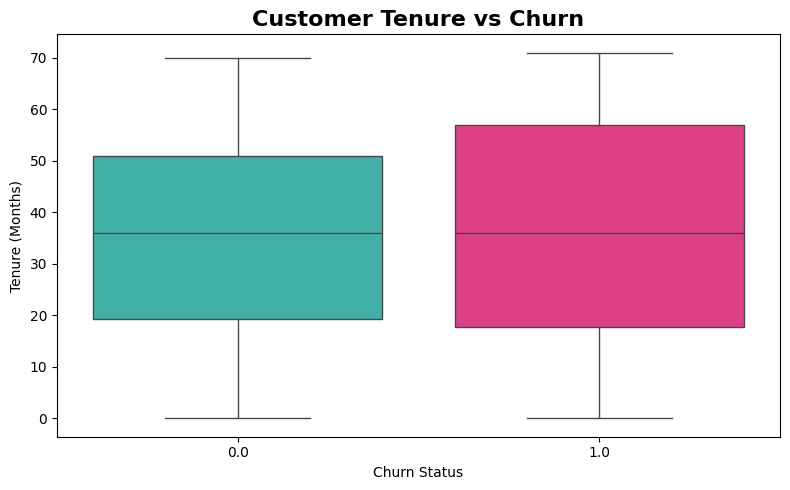

In [292]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='churn',
    y='tenure_months',
    hue='churn',
    palette=['#2EC4B6', '#F72585'],
    legend=False
)

plt.title('Customer Tenure vs Churn', fontsize=16, fontweight='bold')
plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')

plt.tight_layout()
plt.show()

2. Count plot...

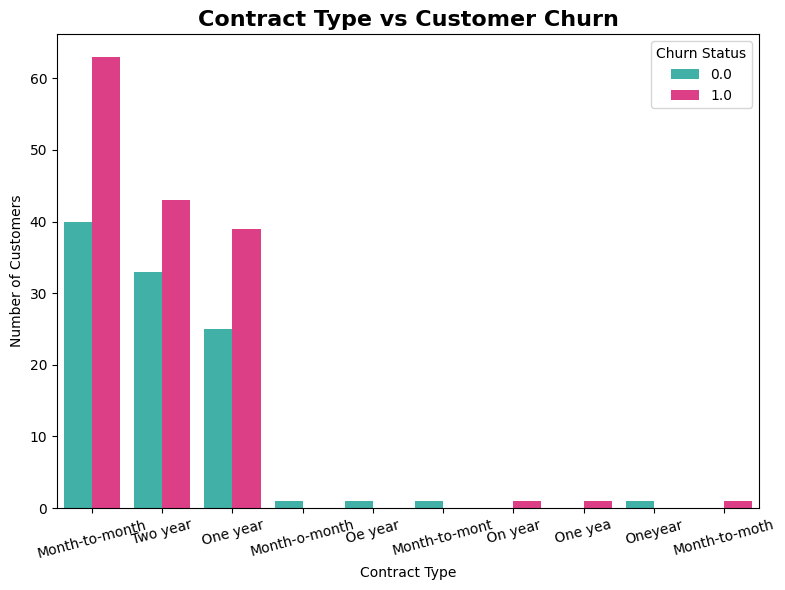

In [293]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x='contract',
    hue='churn',
    palette=['#2EC4B6', '#F72585']
)

plt.title('Contract Type vs Customer Churn', fontsize=16, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn Status')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

3.Scatter plot...

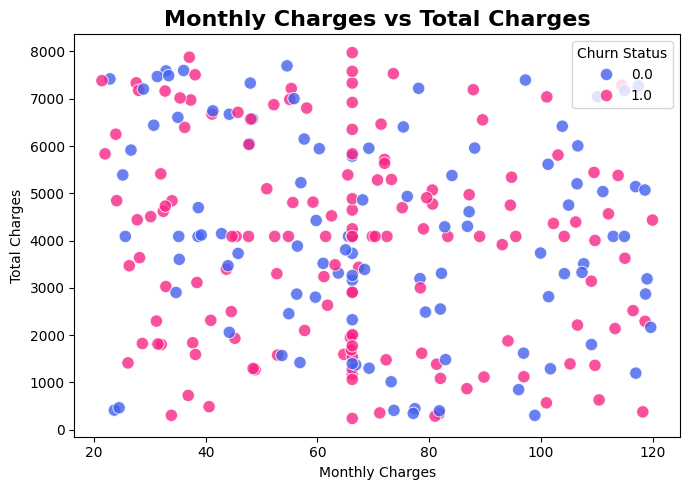

In [294]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x='monthly_charges',
    y='total_charges',
    hue='churn',
    palette=['#4361EE', '#F72585'],
    s=80,
    alpha=0.8
)

plt.title('Monthly Charges vs Total Charges', fontsize=16, fontweight='bold')
plt.xlabel('Monthly Charges')
plt.ylabel('Total Charges')
plt.legend(title='Churn Status')

plt.tight_layout()
plt.show()

3.MULTIVARIATE ANALYSIS

1.Heatmap...

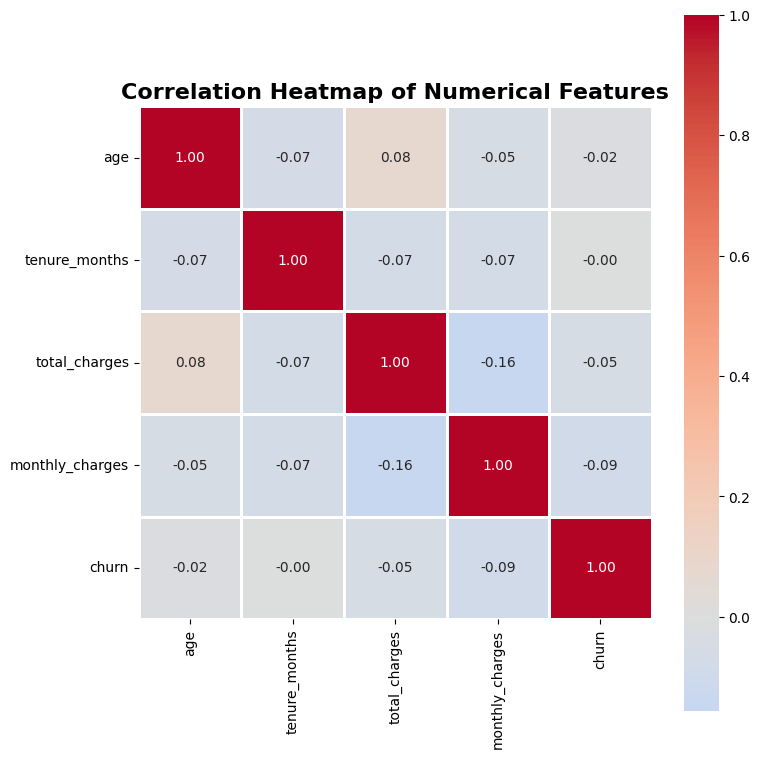

In [295]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.8,
    square=True,
    center=0
)

plt.title('Correlation Heatmap of Numerical Features', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

2.Scatter Plot...

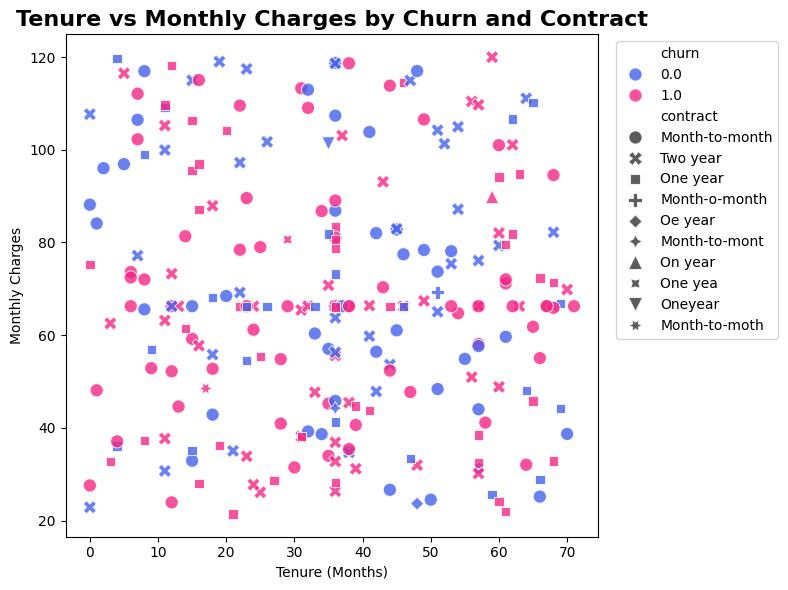

In [296]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='tenure_months',
    y='monthly_charges',
    hue='churn',
    style='contract',
    palette=['#4361EE', '#F72585'],
    s=90,
    alpha=0.8
)

plt.title('Tenure vs Monthly Charges by Churn and Contract',
          fontsize=16, fontweight='bold')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

COMPLETE EDA REPORT - CUSTOMER CHURN ANALYSIS

Exploratory Data Analysis was performed on the cleaned customer churn dataset containing 250 records. Univariate, bivariate, and multivariate analyses were conducted using 12 visualizations. The analysis revealed that 59.2% of customers churned, while 40.8% stayed. Month-to-month contracts were the most common. These findings help identify customer behavior patterns and support better customer retention strategies.